In [35]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import genlaguerre
from sklearn.metrics import roc_auc_score

images_original_filepath = '.\\MRI\\HCP_selected_ones2.npy'
images_original = np.load(images_original_filepath, allow_pickle=True, mmap_mode='r')
n_case_images = min(11_000, images_original.shape[0])
full_image_shape = images_original.shape[1:]
print('Original images shape:', (n_case_images, *full_image_shape))

images_lesion_indices_filepath = '.\\MRI\\images_lesion_indices.bin'
with open(images_lesion_indices_filepath, 'rb') as f:
    images_lesion_indices = np.fromfile(f, dtype=np.int16).reshape((-1, 2))[:n_case_images]
print('Signal-center indices shape:', images_lesion_indices.shape)

images_normal_indices_filepath = '.\\MRI\\images_normal_indices.bin'
with open(images_normal_indices_filepath, 'rb') as f:
    images_normal_indices = np.fromfile(f, dtype=np.int16).reshape((-1, 2))[:n_case_images]
print('Normal-center indices shape:', images_normal_indices.shape)

patch_shape = (64, 64)
selected_lesion_intensities = [0.05, 0.10, 0.20]
reference_lesion_intensity = 0.10
reference_noise_level = 0.10
preview_source_mode = 'lesion'
preview_lesion_intensity = reference_lesion_intensity
preview_noise_level = reference_noise_level
preview_undersampling_factor = 2
noise_search_candidates = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40]
reference_undersampling_factor = 2
train_size = 10_000
test_size = 1_000
calibration_train_size = 2_000
calibration_test_size = 500
random_seed = 0
gabor_width_candidates = [3.0, 5.0, 7.0, 9.0]
lg_scale_candidates = [4.0, 6.0, 8.0]

rng = np.random.default_rng(random_seed)
experiment_indices = rng.permutation(n_case_images)[:train_size + test_size]
calibration_indices = experiment_indices[:calibration_train_size + calibration_test_size]

patch_cache = {}

def build_source_tag(source_mode, lesion_intensity=None):
    if source_mode == 'original':
        return 'original'
    if lesion_intensity is None:
        raise ValueError('lesion_intensity is required when source_mode is lesion.')
    return f'lesion_{lesion_intensity:.2f}'

def build_patch_filepath(kind, source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return (
        f'.\\MRI\\{kind}_patches_source_{source_tag}'
        f'_noise_{noise_level:.2f}_undersample_{undersampling_factor}.bin'
    )

def load_patch_array(kind, source_mode, lesion_intensity, noise_level, undersampling_factor):
    cache_key = (kind, source_mode, lesion_intensity, noise_level, undersampling_factor)
    if cache_key in patch_cache:
        return patch_cache[cache_key]

    patch_filepath = Path(build_patch_filepath(kind, source_mode, lesion_intensity, noise_level, undersampling_factor))
    if not patch_filepath.exists():
        raise FileNotFoundError(
            f'Missing patch file: {patch_filepath}. Run c2_get_patch_datasets.ipynb after c1_add_noise.ipynb.'
        )

    patch_array = np.fromfile(patch_filepath, dtype=np.float32)
    pixels_per_patch = patch_shape[0] * patch_shape[1]
    if patch_array.size % pixels_per_patch != 0:
        raise ValueError(
            f'Unexpected patch file size for {patch_filepath}: got {patch_array.size}, '
            f'which is not divisible by {pixels_per_patch}.'
        )

    n_saved_patches = patch_array.size // pixels_per_patch
    if n_saved_patches < n_case_images:
        raise ValueError(
            f'Patch file {patch_filepath} only contains {n_saved_patches} cases, '
            f'but at least {n_case_images} are required.'
        )

    patch_array = patch_array.reshape((n_saved_patches, *patch_shape))[:n_case_images]
    patch_cache[cache_key] = patch_array
    return patch_array

def load_case_patches(source_mode, lesion_intensity, noise_level, undersampling_factor):
    signal_patches = load_patch_array('signal', source_mode, lesion_intensity, noise_level, undersampling_factor)
    normal_patches = load_patch_array('normal', source_mode, lesion_intensity, noise_level, undersampling_factor)
    return signal_patches, normal_patches

def split_case_data(signal_patches, normal_patches, train_size, test_size):
    return {
        'train_signal_patches': signal_patches[:train_size],
        'train_normal_patches': normal_patches[:train_size],
        'test_signal_patches': signal_patches[train_size:train_size + test_size],
        'test_normal_patches': normal_patches[train_size:train_size + test_size],
    }

Original images shape: (11000, 260, 311)
Signal-center indices shape: (11000, 2)
Normal-center indices shape: (11000, 2)


In [36]:
signal_patches, normal_patches = load_case_patches(
    preview_source_mode,
    lesion_intensity=preview_lesion_intensity,
    noise_level=preview_noise_level,
    undersampling_factor=preview_undersampling_factor,
 )

split_data = split_case_data(
    signal_patches,
    normal_patches,
    train_size=calibration_train_size,
    test_size=calibration_test_size,
 )

train_signal_patches = split_data['train_signal_patches']
train_normal_patches = split_data['train_normal_patches']
test_signal_patches = split_data['test_signal_patches']
test_normal_patches = split_data['test_normal_patches']

print(
    'Preview signal patch file:',
    build_patch_filepath('signal', preview_source_mode, preview_lesion_intensity, preview_noise_level, preview_undersampling_factor),
)
print(
    'Preview normal patch file:',
    build_patch_filepath('normal', preview_source_mode, preview_lesion_intensity, preview_noise_level, preview_undersampling_factor),
)
print('Training signal patches:', train_signal_patches.shape)
print('Training normal patches:', train_normal_patches.shape)
print('Testing signal patches:', test_signal_patches.shape)
print('Testing normal patches:', test_normal_patches.shape)

Preview signal patch file: .\MRI\signal_patches_source_lesion_0.10_noise_0.10_undersample_2.bin
Preview normal patch file: .\MRI\normal_patches_source_lesion_0.10_noise_0.10_undersample_2.bin
Training signal patches: (2000, 64, 64)
Training normal patches: (2000, 64, 64)
Testing signal patches: (500, 64, 64)
Testing normal patches: (500, 64, 64)


In [27]:
def compute_detectability(signal_scores, normal_scores):
    pooled_std = np.sqrt((np.var(signal_scores) + np.var(normal_scores)) / 2.0)
    if pooled_std == 0.0:
        return 0.0
    return float((np.mean(signal_scores) - np.mean(normal_scores)) / pooled_std)

def build_roc_curve(signal_scores, normal_scores, n_thresholds=200):
    thresholds = np.linspace(
        min(signal_scores.min(), normal_scores.min()),
        max(signal_scores.max(), normal_scores.max()),
        n_thresholds,
    )
    roc_curve = [
        (
            np.mean(normal_scores >= threshold),
            np.mean(signal_scores >= threshold),
        )
        for threshold in thresholds
    ]
    return thresholds, roc_curve

def fit_hotelling_observer(train_signal_patches, train_normal_patches, test_signal_patches, test_normal_patches):
    train_signal_flat = train_signal_patches.reshape(train_signal_patches.shape[0], -1)
    train_normal_flat = train_normal_patches.reshape(train_normal_patches.shape[0], -1)
    test_signal_flat = test_signal_patches.reshape(test_signal_patches.shape[0], -1)
    test_normal_flat = test_normal_patches.reshape(test_normal_patches.shape[0], -1)

    signal_mu = np.mean(train_signal_flat, axis=0)
    normal_mu = np.mean(train_normal_flat, axis=0)
    signal_cov = np.cov(train_signal_flat, rowvar=False)
    normal_cov = np.cov(train_normal_flat, rowvar=False)
    covariance = (signal_cov + normal_cov) / 2.0

    eps = 1e-3 * np.trace(covariance) / covariance.shape[0]
    covariance_regularized = covariance + eps * np.eye(covariance.shape[0])
    weights = np.linalg.solve(covariance_regularized, signal_mu - normal_mu)

    train_signal_scores = train_signal_flat @ weights
    train_normal_scores = train_normal_flat @ weights
    test_signal_scores = test_signal_flat @ weights
    test_normal_scores = test_normal_flat @ weights

    train_labels = np.concatenate([np.ones(len(train_signal_scores)), np.zeros(len(train_normal_scores))])
    test_labels = np.concatenate([np.ones(len(test_signal_scores)), np.zeros(len(test_normal_scores))])
    train_scores = np.concatenate([train_signal_scores, train_normal_scores])
    test_scores = np.concatenate([test_signal_scores, test_normal_scores])

    return {
        'signal_mu': signal_mu.reshape(patch_shape),
        'normal_mu': normal_mu.reshape(patch_shape),
        'signal_cov': signal_cov,
        'normal_cov': normal_cov,
        'weights': weights.reshape(patch_shape),
        'train_signal_scores': train_signal_scores,
        'train_normal_scores': train_normal_scores,
        'test_signal_scores': test_signal_scores,
        'test_normal_scores': test_normal_scores,
        'train_detectability': compute_detectability(train_signal_scores, train_normal_scores),
        'test_detectability': compute_detectability(test_signal_scores, test_normal_scores),
        'train_auc': float(roc_auc_score(train_labels, train_scores)),
        'test_auc': float(roc_auc_score(test_labels, test_scores)),
    }

ho_results = fit_hotelling_observer(
    train_signal_patches,
    train_normal_patches,
    test_signal_patches,
    test_normal_patches,
 )
print(f"HO train detectability (d'): {ho_results['train_detectability']:.2f}")
print(f"HO test detectability (d'): {ho_results['test_detectability']:.2f}")
print(f"HO train AUC: {ho_results['train_auc']:.3f}")
print(f"HO test AUC: {ho_results['test_auc']:.3f}")

HO train detectability (d'): 13.05
HO test detectability (d'): 0.77
HO train AUC: 1.000
HO test AUC: 0.706


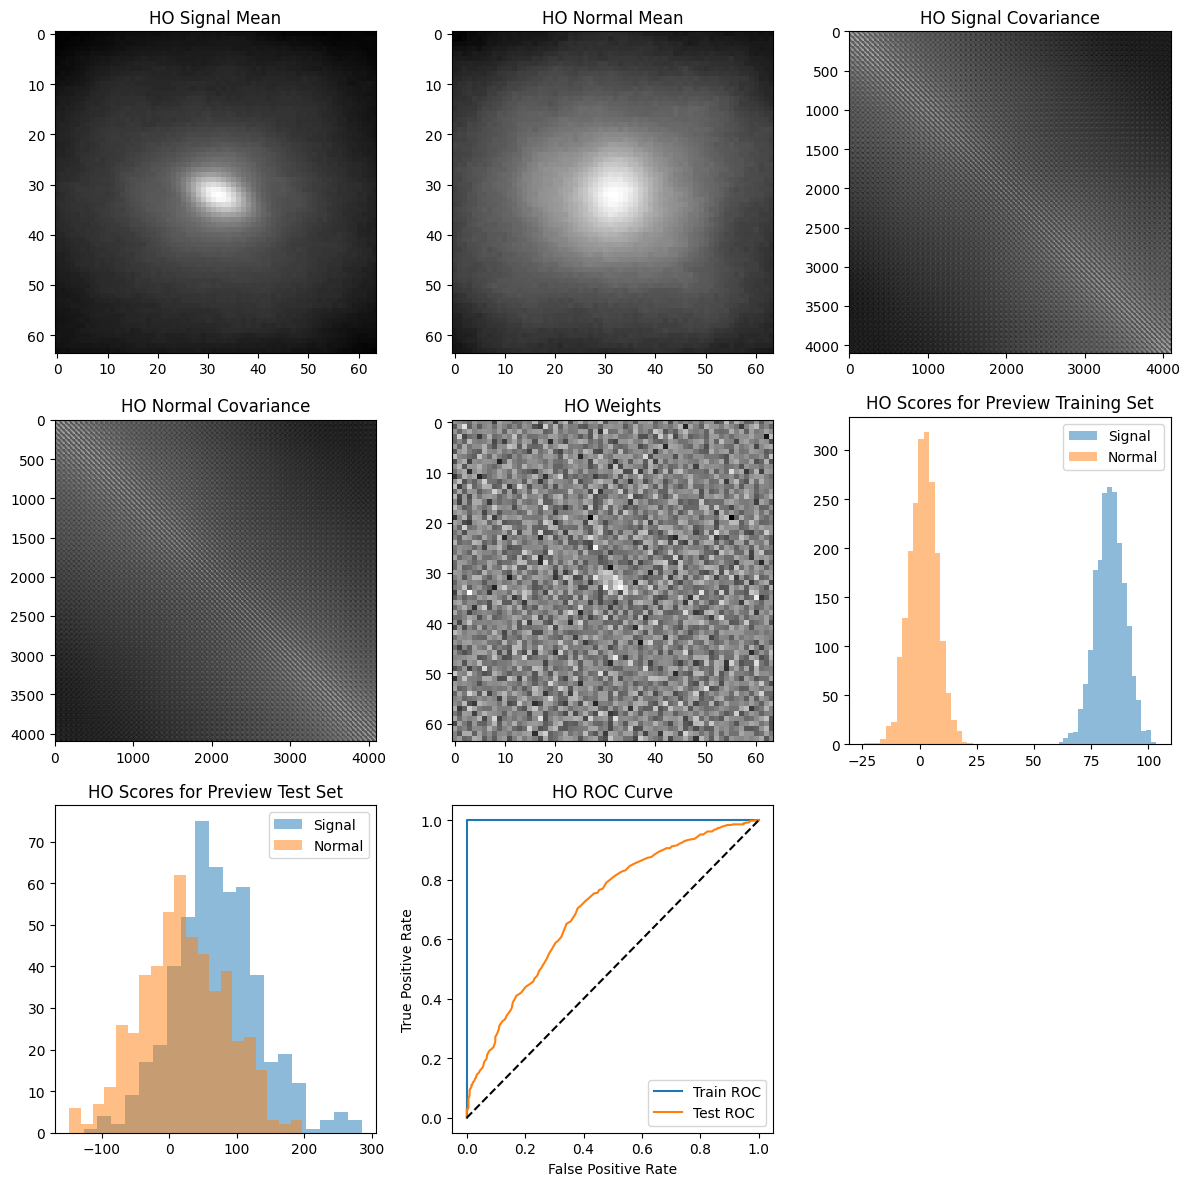

In [28]:
_, ho_train_roc_curve = build_roc_curve(
    ho_results['train_signal_scores'],
    ho_results['train_normal_scores'],
 )
_, ho_test_roc_curve = build_roc_curve(
    ho_results['test_signal_scores'],
    ho_results['test_normal_scores'],
 )

plt.figure(figsize=(12, 12))
plt.subplot(3, 3, 1)
plt.imshow(ho_results['signal_mu'], cmap='gray')
plt.title('HO Signal Mean')

plt.subplot(3, 3, 2)
plt.imshow(ho_results['normal_mu'], cmap='gray')
plt.title('HO Normal Mean')

plt.subplot(3, 3, 3)
plt.imshow(ho_results['signal_cov'], cmap='gray')
plt.title('HO Signal Covariance')

plt.subplot(3, 3, 4)
plt.imshow(ho_results['normal_cov'], cmap='gray')
plt.title('HO Normal Covariance')

plt.subplot(3, 3, 5)
plt.imshow(ho_results['weights'], cmap='gray')
plt.title('HO Weights')

plt.subplot(3, 3, 6)
plt.hist(ho_results['train_signal_scores'], bins=20, alpha=0.5, label='Signal')
plt.hist(ho_results['train_normal_scores'], bins=20, alpha=0.5, label='Normal')
plt.title('HO Scores for Preview Training Set')
plt.legend()

plt.subplot(3, 3, 7)
plt.hist(ho_results['test_signal_scores'], bins=20, alpha=0.5, label='Signal')
plt.hist(ho_results['test_normal_scores'], bins=20, alpha=0.5, label='Normal')
plt.title('HO Scores for Preview Test Set')
plt.legend()

plt.subplot(3, 3, 8)
plt.plot([fp for fp, tp in ho_train_roc_curve], [tp for fp, tp in ho_train_roc_curve], label='Train ROC')
plt.plot([fp for fp, tp in ho_test_roc_curve], [tp for fp, tp in ho_test_roc_curve], label='Test ROC')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('HO ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
def build_gabor_channels(patch_shape, width, n_thetas=8, phases_deg=(0.0, 90.0)):
    ys = np.arange(-(patch_shape[0] // 2), patch_shape[0] // 2)
    xs = np.arange(-(patch_shape[1] // 2), patch_shape[1] // 2)
    yys, xxs = np.meshgrid(ys, xs, indexing='ij')

    channels = []
    for theta_deg in np.linspace(0, 180, n_thetas, endpoint=False):
        theta = np.deg2rad(theta_deg)
        for phase_deg in phases_deg:
            phase = np.deg2rad(phase_deg)
            frequency = 1.0 / width
            envelope = np.exp(-4 * np.log(2) * (xxs**2 + yys**2) / (width**2))
            carrier = np.cos(2 * np.pi * frequency * (xxs * np.cos(theta) + yys * np.sin(theta)) + phase)
            channels.append((envelope * carrier).reshape(-1))

    channels.append(np.ones(patch_shape[0] * patch_shape[1], dtype=np.float32))
    return np.column_stack(channels).astype(np.float32)

def build_lg_channels(patch_shape, scale, radial_orders=(0, 1, 2), angular_orders=(0, 1)):
    ys = np.arange(-(patch_shape[0] // 2), patch_shape[0] // 2)
    xs = np.arange(-(patch_shape[1] // 2), patch_shape[1] // 2)
    yys, xxs = np.meshgrid(ys, xs, indexing='ij')
    rr = np.sqrt(xxs**2 + yys**2) / scale
    theta = np.arctan2(yys, xxs)
    radial_coordinate = 2.0 * rr**2

    channels = []
    for radial_order in radial_orders:
        base_polynomial = genlaguerre(radial_order, 0)(radial_coordinate)
        base_channel = np.exp(-rr**2) * base_polynomial
        channels.append(base_channel.reshape(-1))

        for angular_order in angular_orders:
            if angular_order == 0:
                continue
            angular_polynomial = genlaguerre(radial_order, angular_order)(radial_coordinate)
            angular_envelope = ((np.sqrt(2.0) * rr) ** angular_order) * np.exp(-rr**2) * angular_polynomial
            channels.append((angular_envelope * np.cos(angular_order * theta)).reshape(-1))
            channels.append((angular_envelope * np.sin(angular_order * theta)).reshape(-1))

    channels.append(np.ones(patch_shape[0] * patch_shape[1], dtype=np.float32))
    return np.column_stack(channels).astype(np.float32)

current_gabor_width = 5.0
current_lg_scale = 6.0
gabor_channels_matrix = build_gabor_channels(patch_shape, current_gabor_width)
lg_channels_matrix = build_lg_channels(patch_shape, current_lg_scale)
print('Gabor channel matrix shape:', gabor_channels_matrix.shape)
print('LG channel matrix shape:', lg_channels_matrix.shape)

Gabor channel matrix shape: (4096, 17)
LG channel matrix shape: (4096, 10)


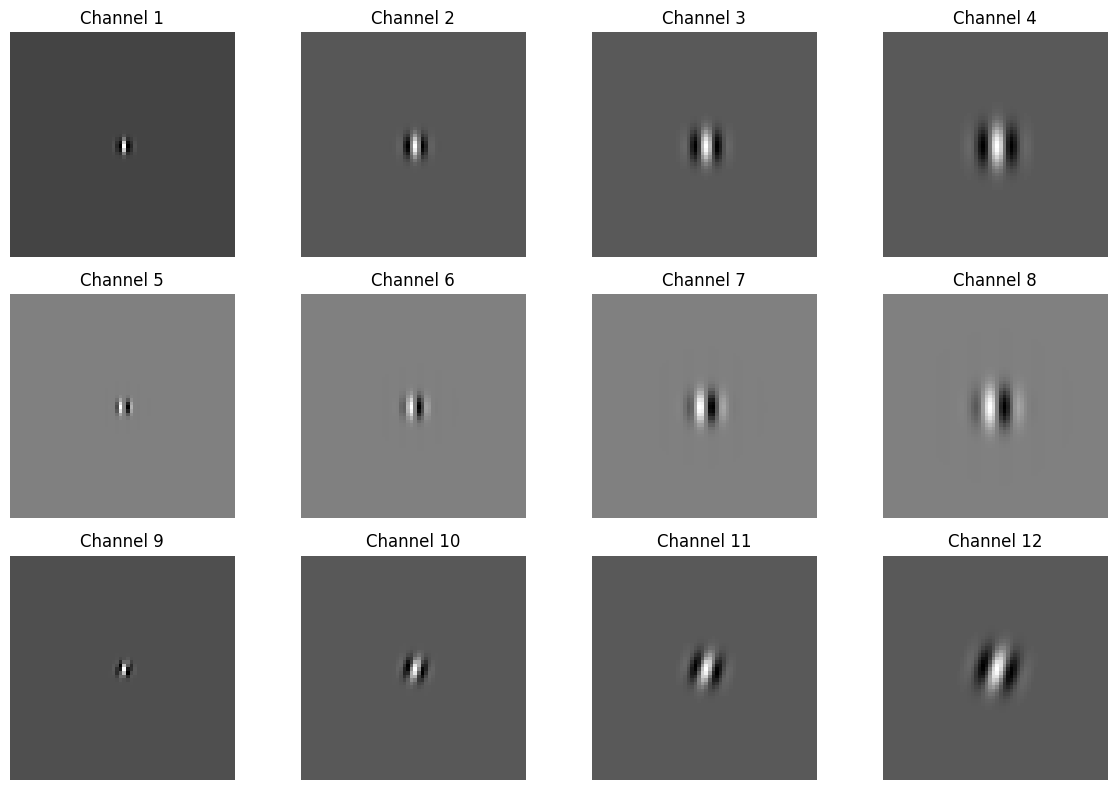

In [ ]:
plt.figure(figsize=(12, 6))
n_preview_channels = min(6, gabor_channels_matrix.shape[1] - 1)
for channel_i in range(n_preview_channels):
    plt.subplot(2, 6, channel_i + 1)
    plt.imshow(gabor_channels_matrix[:, channel_i].reshape(patch_shape), cmap='gray')
    plt.title(f'Gabor {channel_i + 1}')
    plt.axis('off')

for channel_i in range(n_preview_channels):
    plt.subplot(2, 6, n_preview_channels + channel_i + 1)
    plt.imshow(lg_channels_matrix[:, channel_i].reshape(patch_shape), cmap='gray')
    plt.title(f'LG {channel_i + 1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [18]:
def fit_channelized_hotelling_observer(train_signal_patches, train_normal_patches, test_signal_patches, test_normal_patches, channels_matrix):
    train_signal_flat = train_signal_patches.reshape(train_signal_patches.shape[0], -1)
    train_normal_flat = train_normal_patches.reshape(train_normal_patches.shape[0], -1)
    test_signal_flat = test_signal_patches.reshape(test_signal_patches.shape[0], -1)
    test_normal_flat = test_normal_patches.reshape(test_normal_patches.shape[0], -1)

    train_signal_channels = train_signal_flat @ channels_matrix
    train_normal_channels = train_normal_flat @ channels_matrix
    test_signal_channels = test_signal_flat @ channels_matrix
    test_normal_channels = test_normal_flat @ channels_matrix

    signal_mu = np.mean(train_signal_channels, axis=0)
    normal_mu = np.mean(train_normal_channels, axis=0)
    signal_cov = np.cov(train_signal_channels, rowvar=False)
    normal_cov = np.cov(train_normal_channels, rowvar=False)
    covariance = (signal_cov + normal_cov) / 2.0

    eps = 1e-3 * np.trace(covariance) / covariance.shape[0]
    covariance_regularized = covariance + eps * np.eye(covariance.shape[0])
    weights = np.linalg.solve(covariance_regularized, signal_mu - normal_mu)

    train_signal_scores = train_signal_channels @ weights
    train_normal_scores = train_normal_channels @ weights
    test_signal_scores = test_signal_channels @ weights
    test_normal_scores = test_normal_channels @ weights

    train_labels = np.concatenate([np.ones(len(train_signal_scores)), np.zeros(len(train_normal_scores))])
    test_labels = np.concatenate([np.ones(len(test_signal_scores)), np.zeros(len(test_normal_scores))])
    train_scores = np.concatenate([train_signal_scores, train_normal_scores])
    test_scores = np.concatenate([test_signal_scores, test_normal_scores])

    return {
        'signal_mu': signal_mu,
        'normal_mu': normal_mu,
        'signal_cov': signal_cov,
        'normal_cov': normal_cov,
        'weights': weights,
        'train_signal_scores': train_signal_scores,
        'train_normal_scores': train_normal_scores,
        'test_signal_scores': test_signal_scores,
        'test_normal_scores': test_normal_scores,
        'train_detectability': compute_detectability(train_signal_scores, train_normal_scores),
        'test_detectability': compute_detectability(test_signal_scores, test_normal_scores),
        'train_auc': float(roc_auc_score(train_labels, train_scores)),
        'test_auc': float(roc_auc_score(test_labels, test_scores)),
    }

gabor_preview_results = fit_channelized_hotelling_observer(
    train_signal_patches,
    train_normal_patches,
    test_signal_patches,
    test_normal_patches,
    gabor_channels_matrix,
 )
lg_preview_results = fit_channelized_hotelling_observer(
    train_signal_patches,
    train_normal_patches,
    test_signal_patches,
    test_normal_patches,
    lg_channels_matrix,
 )
print(f"Gabor CHO test AUC: {gabor_preview_results['test_auc']:.3f}")
print(f"LG CHO test AUC: {lg_preview_results['test_auc']:.3f}")

Gabor CHO test AUC: 0.762
LG CHO test AUC: 0.872


Chosen amplitude 0.100, noise 0.30: 250/250 patches done
Chosen amplitude 0.100, noise 0.10: 250/250 patches done
Chosen amplitude 0.100, noise 0.02: 250/250 patches done
Chosen amplitude 0.100, undersample 2: 250/250 patches done
Chosen amplitude 0.100, undersample 4: 250/250 patches done


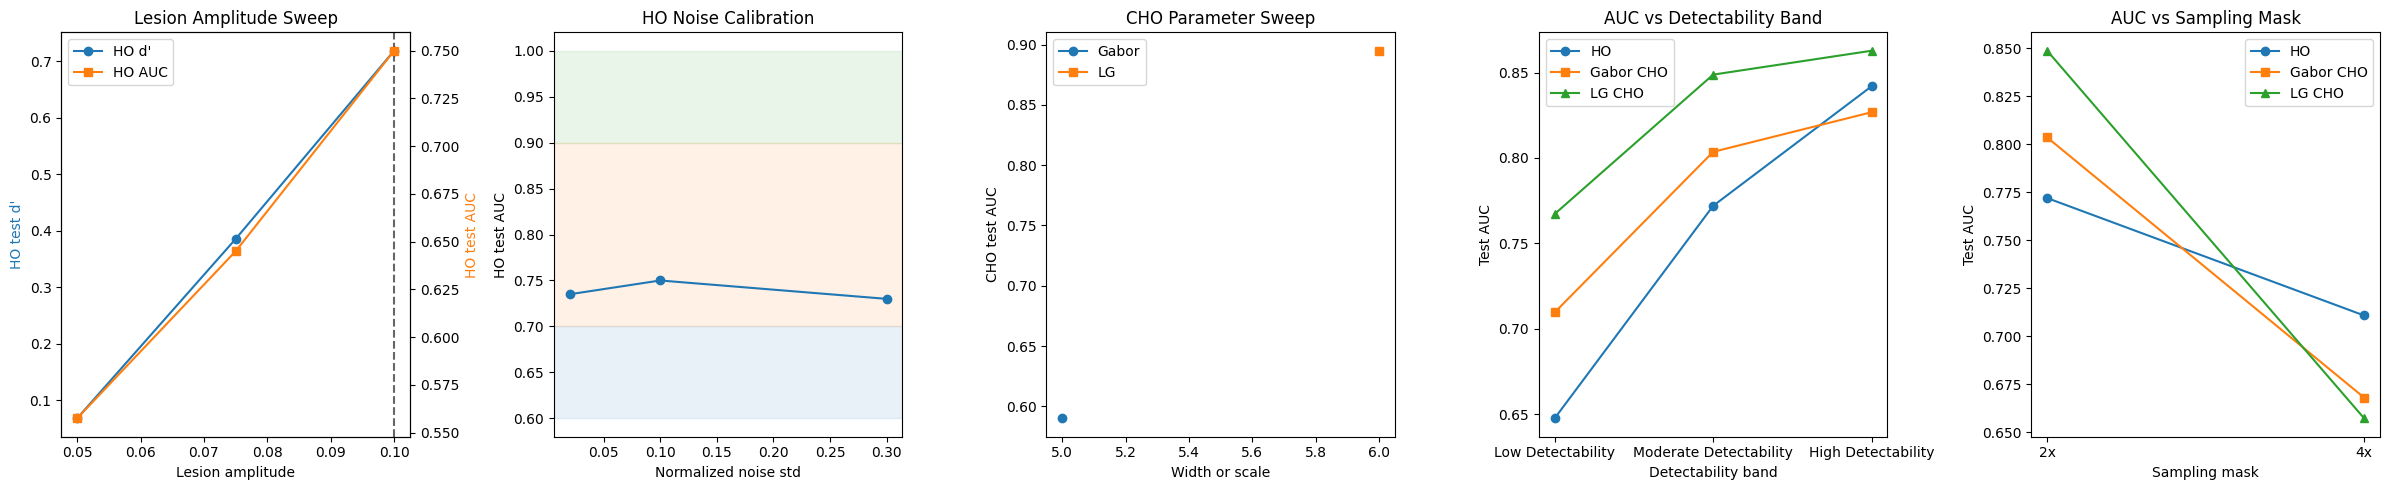

Lesion amplitude sweep at fixed reference settings:
  normalized_noise=0.10, raw_kspace_sigma=20.11, undersampling=2x
  amplitude=0.050, HO d'=0.068, HO AUC=0.557, Gabor CHO AUC=0.518, LG CHO AUC=0.770
  amplitude=0.075, HO d'=0.386, HO AUC=0.645, Gabor CHO AUC=0.550, LG CHO AUC=0.843
  amplitude=0.100, HO d'=0.719, HO AUC=0.750, Gabor CHO AUC=0.590, LG CHO AUC=0.895
Selected lesion amplitude: 0.100 (closest HO AUC to the middle of the moderate detectability band under the fixed reference setting)
Selected noise levels for the chosen lesion amplitude:
  detectability_band=low_detectability, normalized_noise=0.30, raw_kspace_sigma=60.32, HO d'=0.738, HO AUC=0.730
  detectability_band=moderate_detectability, normalized_noise=0.10, raw_kspace_sigma=20.11, HO d'=0.719, HO AUC=0.750
  detectability_band=high_detectability, normalized_noise=0.02, raw_kspace_sigma=4.02, HO d'=0.589, HO AUC=0.735
Best Gabor width=5.00, best LG scale=6.00
Detectability band=low_detectability, normalized_noise=0

In [ ]:
def noise_level_to_raw_kspace_component_sigma(noise_level):
    return float(noise_level * np.sqrt(np.prod(full_image_shape) / 2.0))

detectability_band_order = [
    'low_detectability',
    'moderate_detectability',
    'high_detectability',
]

def format_detectability_band_name(band_name):
    return band_name.replace('_', ' ').title()

def evaluate_case(indices, train_size, test_size, source_mode, lesion_intensity, noise_level, undersampling_factor, gabor_width, lg_scale, progress_label=None):
    if progress_label is not None:
        print(f"Using saved patch files for {progress_label}")

    signal_patches, normal_patches = load_case_patches(
        source_mode,
        lesion_intensity,
        noise_level,
        undersampling_factor,
    )
    case_indices = np.asarray(indices[:train_size + test_size], dtype=int)
    split_data = split_case_data(
        signal_patches[case_indices],
        normal_patches[case_indices],
        train_size=train_size,
        test_size=test_size,
    )
    ho_case_results = fit_hotelling_observer(
        split_data['train_signal_patches'],
        split_data['train_normal_patches'],
        split_data['test_signal_patches'],
        split_data['test_normal_patches'],
    )
    gabor_case_results = fit_channelized_hotelling_observer(
        split_data['train_signal_patches'],
        split_data['train_normal_patches'],
        split_data['test_signal_patches'],
        split_data['test_normal_patches'],
        build_gabor_channels(patch_shape, gabor_width),
    )
    lg_case_results = fit_channelized_hotelling_observer(
        split_data['train_signal_patches'],
        split_data['train_normal_patches'],
        split_data['test_signal_patches'],
        split_data['test_normal_patches'],
        build_lg_channels(patch_shape, lg_scale),
    )
    return {
        'ho': ho_case_results,
        'gabor': gabor_case_results,
        'lg': lg_case_results,
        'split_data': split_data,
    }

def select_noise_levels_from_bands(calibration_results):
    target_bands = [
        ('low_detectability', (0.60, 0.70)),
        ('moderate_detectability', (0.70, 0.90)),
        ('high_detectability', (0.90, 1.01)),
    ]
    selected_results = {}
    used_noise_levels = set()

    for band_name, (band_low, band_high) in target_bands:
        band_mid = (band_low + min(band_high, 1.0)) / 2.0
        ranked_results = sorted(
            calibration_results,
            key=lambda result: (
                0 if band_low <= result['ho_test_auc'] < band_high else 1,
                abs(result['ho_test_auc'] - band_mid),
            ),
        )
        for result in ranked_results:
            if result['noise_level'] in used_noise_levels:
                continue
            selected_results[band_name] = result
            used_noise_levels.add(result['noise_level'])
            break

    return selected_results

def select_lesion_intensity_from_sweep(lesion_sweep_results, target_auc=0.80):
    ranked_results = sorted(
        lesion_sweep_results,
        key=lambda result: (
            0 if 0.70 <= result['ho_test_auc'] < 0.90 else 1,
            abs(result['ho_test_auc'] - target_auc),
            abs(result['ho_test_detectability'] - 2.0),
        ),
    )
    return ranked_results[0]

lesion_sweep_amplitudes = selected_lesion_intensities
lesion_sweep_noise_level = reference_noise_level
lesion_sweep_undersampling_factor = reference_undersampling_factor
lesion_sweep_results = []

for lesion_intensity in lesion_sweep_amplitudes:
    evaluation_results = evaluate_case(
        calibration_indices,
        train_size=calibration_train_size,
        test_size=calibration_test_size,
        source_mode='lesion',
        lesion_intensity=lesion_intensity,
        noise_level=lesion_sweep_noise_level,
        undersampling_factor=lesion_sweep_undersampling_factor,
        gabor_width=current_gabor_width,
        lg_scale=current_lg_scale,
        progress_label=None,
    )
    lesion_sweep_results.append({
        'lesion_intensity': lesion_intensity,
        'noise_level': lesion_sweep_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(lesion_sweep_noise_level),
        'undersampling_factor': lesion_sweep_undersampling_factor,
        'ho_test_detectability': evaluation_results['ho']['test_detectability'],
        'ho_test_auc': evaluation_results['ho']['test_auc'],
        'gabor_test_auc': evaluation_results['gabor']['test_auc'],
        'lg_test_auc': evaluation_results['lg']['test_auc'],
    })

chosen_lesion_result = select_lesion_intensity_from_sweep(lesion_sweep_results)
chosen_lesion_intensity = chosen_lesion_result['lesion_intensity']

calibration_results = []
for candidate_noise_level in noise_search_candidates:
    candidate_results = evaluate_case(
        calibration_indices,
        train_size=calibration_train_size,
        test_size=calibration_test_size,
        source_mode='lesion',
        lesion_intensity=chosen_lesion_intensity,
        noise_level=candidate_noise_level,
        undersampling_factor=reference_undersampling_factor,
        gabor_width=current_gabor_width,
        lg_scale=current_lg_scale,
        progress_label=None,
    )
    calibration_results.append({
        'noise_level': candidate_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(candidate_noise_level),
        'ho_test_detectability': candidate_results['ho']['test_detectability'],
        'ho_test_auc': candidate_results['ho']['test_auc'],
    })

selected_noise_levels = select_noise_levels_from_bands(calibration_results)
moderate_noise_level = selected_noise_levels['moderate_detectability']['noise_level']

moderate_signal_patches, moderate_normal_patches = load_case_patches(
    'lesion',
    chosen_lesion_intensity,
    moderate_noise_level,
    reference_undersampling_factor,
 )
moderate_case_indices = np.asarray(
    calibration_indices[:calibration_train_size + calibration_test_size],
    dtype=int,
 )
moderate_split_data = split_case_data(
    moderate_signal_patches[moderate_case_indices],
    moderate_normal_patches[moderate_case_indices],
    train_size=calibration_train_size,
    test_size=calibration_test_size,
 )

gabor_parameter_results = []
for gabor_width in gabor_width_candidates:
    gabor_results = fit_channelized_hotelling_observer(
        moderate_split_data['train_signal_patches'],
        moderate_split_data['train_normal_patches'],
        moderate_split_data['test_signal_patches'],
        moderate_split_data['test_normal_patches'],
        build_gabor_channels(patch_shape, gabor_width),
    )
    gabor_parameter_results.append({
        'width': gabor_width,
        'test_auc': gabor_results['test_auc'],
    })

lg_parameter_results = []
for lg_scale in lg_scale_candidates:
    lg_results = fit_channelized_hotelling_observer(
        moderate_split_data['train_signal_patches'],
        moderate_split_data['train_normal_patches'],
        moderate_split_data['test_signal_patches'],
        moderate_split_data['test_normal_patches'],
        build_lg_channels(patch_shape, lg_scale),
    )
    lg_parameter_results.append({
        'scale': lg_scale,
        'test_auc': lg_results['test_auc'],
    })

best_gabor_width = max(gabor_parameter_results, key=lambda result: result['test_auc'])['width']
best_lg_scale = max(lg_parameter_results, key=lambda result: result['test_auc'])['scale']

noise_summary_results = []
for band_name in detectability_band_order:
    selected_noise_level = selected_noise_levels[band_name]['noise_level']
    evaluation_results = evaluate_case(
        experiment_indices,
        train_size=train_size,
        test_size=test_size,
        source_mode='lesion',
        lesion_intensity=chosen_lesion_intensity,
        noise_level=selected_noise_level,
        undersampling_factor=reference_undersampling_factor,
        gabor_width=best_gabor_width,
        lg_scale=best_lg_scale,
        progress_label=f"chosen_amplitude={chosen_lesion_intensity:.3f}, noise={selected_noise_level:.3f}",
    )
    noise_summary_results.append({
        'band': band_name,
        'band_label': format_detectability_band_name(band_name),
        'noise_level': selected_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(selected_noise_level),
        'ho_test_detectability': evaluation_results['ho']['test_detectability'],
        'ho_test_auc': evaluation_results['ho']['test_auc'],
        'gabor_test_auc': evaluation_results['gabor']['test_auc'],
        'lg_test_auc': evaluation_results['lg']['test_auc'],
    })

sampling_summary_results = []
for undersampling_factor in [2, 4]:
    evaluation_results = evaluate_case(
        experiment_indices,
        train_size=train_size,
        test_size=test_size,
        source_mode='lesion',
        lesion_intensity=chosen_lesion_intensity,
        noise_level=moderate_noise_level,
        undersampling_factor=undersampling_factor,
        gabor_width=best_gabor_width,
        lg_scale=best_lg_scale,
        progress_label=f"chosen_amplitude={chosen_lesion_intensity:.3f}, undersample={undersampling_factor}",
    )
    sampling_summary_results.append({
        'undersampling_factor': undersampling_factor,
        'noise_level': moderate_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(moderate_noise_level),
        'ho_test_detectability': evaluation_results['ho']['test_detectability'],
        'ho_test_auc': evaluation_results['ho']['test_auc'],
        'gabor_test_auc': evaluation_results['gabor']['test_auc'],
        'lg_test_auc': evaluation_results['lg']['test_auc'],
    })

calibration_analysis_summary = {
    'lesion_sweep_results': lesion_sweep_results,
    'chosen_lesion_result': chosen_lesion_result,
    'calibration_results': calibration_results,
    'selected_noise_levels': selected_noise_levels,
    'best_gabor_width': best_gabor_width,
    'best_lg_scale': best_lg_scale,
    'noise_summary_results': noise_summary_results,
    'sampling_summary_results': sampling_summary_results,
    'gabor_parameter_results': gabor_parameter_results,
    'lg_parameter_results': lg_parameter_results,
}

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

lesion_amplitudes = [result['lesion_intensity'] for result in lesion_sweep_results]
lesion_detectabilities = [result['ho_test_detectability'] for result in lesion_sweep_results]
lesion_aucs = [result['ho_test_auc'] for result in lesion_sweep_results]
axes[0].plot(lesion_amplitudes, lesion_detectabilities, marker='o', color='tab:blue', label="HO d'")
axes0_twin = axes[0].twinx()
axes0_twin.plot(lesion_amplitudes, lesion_aucs, marker='s', color='tab:orange', label='HO AUC')
axes[0].axvline(chosen_lesion_intensity, color='k', linestyle='--', alpha=0.6)
axes[0].set_title('Lesion Amplitude Sweep')
axes[0].set_xlabel('Lesion amplitude')
axes[0].set_ylabel("HO test d'", color='tab:blue')
axes0_twin.set_ylabel('HO test AUC', color='tab:orange')
lines_left, labels_left = axes[0].get_legend_handles_labels()
lines_right, labels_right = axes0_twin.get_legend_handles_labels()
axes[0].legend(lines_left + lines_right, labels_left + labels_right, loc='best')

calibration_noise_levels = [result['noise_level'] for result in calibration_results]
calibration_auc_values = [result['ho_test_auc'] for result in calibration_results]
axes[1].plot(calibration_noise_levels, calibration_auc_values, marker='o')
axes[1].axhspan(0.60, 0.70, color='tab:blue', alpha=0.1)
axes[1].axhspan(0.70, 0.90, color='tab:orange', alpha=0.1)
axes[1].axhspan(0.90, 1.00, color='tab:green', alpha=0.1)
axes[1].set_title('HO Noise Calibration')
axes[1].set_xlabel('Normalized noise std')
axes[1].set_ylabel('HO test AUC')

axes[2].plot(
    [result['width'] for result in gabor_parameter_results],
    [result['test_auc'] for result in gabor_parameter_results],
    marker='o',
    label='Gabor',
)
axes[2].plot(
    [result['scale'] for result in lg_parameter_results],
    [result['test_auc'] for result in lg_parameter_results],
    marker='s',
    label='LG',
)
axes[2].set_title('CHO Parameter Sweep')
axes[2].set_xlabel('Width or scale')
axes[2].set_ylabel('CHO test AUC')
axes[2].legend()

noise_labels = [result['band_label'] for result in noise_summary_results]
axes[3].plot(noise_labels, [result['ho_test_auc'] for result in noise_summary_results], marker='o', label='HO')
axes[3].plot(noise_labels, [result['gabor_test_auc'] for result in noise_summary_results], marker='s', label='Gabor CHO')
axes[3].plot(noise_labels, [result['lg_test_auc'] for result in noise_summary_results], marker='^', label='LG CHO')
axes[3].set_title('AUC vs Detectability Band')
axes[3].set_xlabel('Detectability band')
axes[3].set_ylabel('Test AUC')
axes[3].legend()

sampling_labels = [f"{result['undersampling_factor']}x" for result in sampling_summary_results]
axes[4].plot(sampling_labels, [result['ho_test_auc'] for result in sampling_summary_results], marker='o', label='HO')
axes[4].plot(sampling_labels, [result['gabor_test_auc'] for result in sampling_summary_results], marker='s', label='Gabor CHO')
axes[4].plot(sampling_labels, [result['lg_test_auc'] for result in sampling_summary_results], marker='^', label='LG CHO')
axes[4].set_title('AUC vs Sampling Mask')
axes[4].set_xlabel('Sampling mask')
axes[4].set_ylabel('Test AUC')
axes[4].legend()

plt.tight_layout()
plt.show()

print('Lesion amplitude sweep at fixed reference settings:')
print(
    f"  normalized_noise={lesion_sweep_noise_level:.2f}, "
    f"raw_kspace_sigma={noise_level_to_raw_kspace_component_sigma(lesion_sweep_noise_level):.2f}, "
    f"undersampling={lesion_sweep_undersampling_factor}x"
 )
for result in lesion_sweep_results:
    print(
        f"  amplitude={result['lesion_intensity']:.3f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}, "
        f"Gabor CHO AUC={result['gabor_test_auc']:.3f}, "
        f"LG CHO AUC={result['lg_test_auc']:.3f}"
    )

print(
    f"Selected lesion amplitude: {chosen_lesion_result['lesion_intensity']:.3f} "
    f"(closest HO AUC to the middle of the moderate detectability band under the fixed reference setting)"
 )

print('Selected noise levels for the chosen lesion amplitude:')
for band_name in detectability_band_order:
    result = selected_noise_levels[band_name]
    print(
        f"  detectability_band={band_name}, normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}"
    )

print(
    f"Best Gabor width={best_gabor_width:.2f}, "
    f"best LG scale={best_lg_scale:.2f}"
 )

for result in noise_summary_results:
    print(
        f"Detectability band={result['band']}, normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}, "
        f"Gabor CHO AUC={result['gabor_test_auc']:.3f}, "
        f"LG CHO AUC={result['lg_test_auc']:.3f}"
    )

for result in sampling_summary_results:
    print(
        f"Sampling={result['undersampling_factor']}x at normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}, "
        f"Gabor CHO AUC={result['gabor_test_auc']:.3f}, "
        f"LG CHO AUC={result['lg_test_auc']:.3f}"
    )

Refined amplitude 0.100, noise 0.300: 250/250 patches done
Refined amplitude 0.100, noise 0.100: 250/250 patches done
Refined amplitude 0.100, noise 0.005: 250/250 patches done
Refined amplitude 0.100, undersample 2: 250/250 patches done
Refined amplitude 0.100, undersample 4: 250/250 patches done


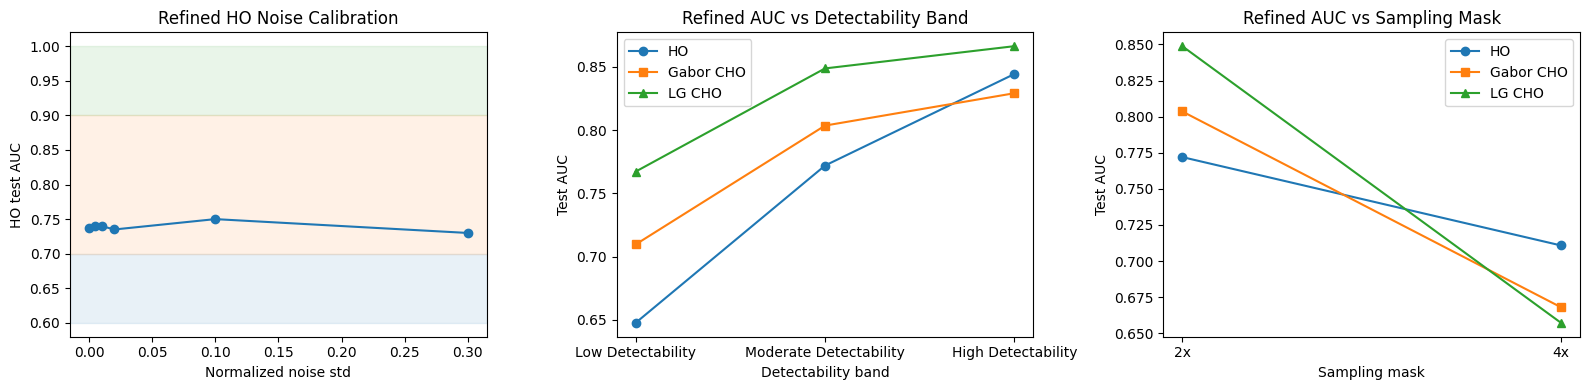

Refined noise calibration with expanded low-noise candidates:
  detectability_band=low_detectability, normalized_noise=0.300, raw_kspace_sigma=60.32, HO d'=0.738, HO AUC=0.730
  detectability_band=moderate_detectability, normalized_noise=0.100, raw_kspace_sigma=20.11, HO d'=0.719, HO AUC=0.750
  detectability_band=high_detectability, normalized_noise=0.005, raw_kspace_sigma=1.01, HO d'=0.568, HO AUC=0.740
Refined best Gabor width=5.00, refined best LG scale=6.00
Detectability band=low_detectability, normalized_noise=0.300, raw_kspace_sigma=60.32, HO d'=0.597, HO AUC=0.648, Gabor CHO AUC=0.710, LG CHO AUC=0.767
Detectability band=moderate_detectability, normalized_noise=0.100, raw_kspace_sigma=20.11, HO d'=1.050, HO AUC=0.772, Gabor CHO AUC=0.804, LG CHO AUC=0.849
Detectability band=high_detectability, normalized_noise=0.005, raw_kspace_sigma=1.01, HO d'=1.383, HO AUC=0.844, Gabor CHO AUC=0.829, LG CHO AUC=0.866
Sampling=2x at normalized_noise=0.100, raw_kspace_sigma=20.11, HO d'=1.050,

In [ ]:
expanded_noise_search_candidates = sorted(set([0.00, 0.005, 0.01] + noise_search_candidates))

refined_calibration_results = []
for candidate_noise_level in expanded_noise_search_candidates:
    candidate_results = evaluate_case(
        calibration_indices,
        train_size=calibration_train_size,
        test_size=calibration_test_size,
        source_mode='lesion',
        lesion_intensity=chosen_lesion_intensity,
        noise_level=candidate_noise_level,
        undersampling_factor=reference_undersampling_factor,
        gabor_width=current_gabor_width,
        lg_scale=current_lg_scale,
        progress_label=None,
    )
    refined_calibration_results.append({
        'noise_level': candidate_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(candidate_noise_level),
        'ho_test_detectability': candidate_results['ho']['test_detectability'],
        'ho_test_auc': candidate_results['ho']['test_auc'],
    })

refined_selected_noise_levels = select_noise_levels_from_bands(refined_calibration_results)
refined_moderate_noise_level = refined_selected_noise_levels['moderate_detectability']['noise_level']

refined_moderate_signal_patches, refined_moderate_normal_patches = load_case_patches(
    'lesion',
    chosen_lesion_intensity,
    refined_moderate_noise_level,
    reference_undersampling_factor,
 )
refined_moderate_case_indices = np.asarray(
    calibration_indices[:calibration_train_size + calibration_test_size],
    dtype=int,
 )
refined_moderate_split_data = split_case_data(
    refined_moderate_signal_patches[refined_moderate_case_indices],
    refined_moderate_normal_patches[refined_moderate_case_indices],
    train_size=calibration_train_size,
    test_size=calibration_test_size,
 )

refined_gabor_parameter_results = []
for gabor_width in gabor_width_candidates:
    gabor_results = fit_channelized_hotelling_observer(
        refined_moderate_split_data['train_signal_patches'],
        refined_moderate_split_data['train_normal_patches'],
        refined_moderate_split_data['test_signal_patches'],
        refined_moderate_split_data['test_normal_patches'],
        build_gabor_channels(patch_shape, gabor_width),
    )
    refined_gabor_parameter_results.append({
        'width': gabor_width,
        'test_auc': gabor_results['test_auc'],
    })

refined_lg_parameter_results = []
for lg_scale in lg_scale_candidates:
    lg_results = fit_channelized_hotelling_observer(
        refined_moderate_split_data['train_signal_patches'],
        refined_moderate_split_data['train_normal_patches'],
        refined_moderate_split_data['test_signal_patches'],
        refined_moderate_split_data['test_normal_patches'],
        build_lg_channels(patch_shape, lg_scale),
    )
    refined_lg_parameter_results.append({
        'scale': lg_scale,
        'test_auc': lg_results['test_auc'],
    })

refined_best_gabor_width = max(refined_gabor_parameter_results, key=lambda result: result['test_auc'])['width']
refined_best_lg_scale = max(refined_lg_parameter_results, key=lambda result: result['test_auc'])['scale']

refined_noise_summary_results = []
for band_name in detectability_band_order:
    selected_noise_level = refined_selected_noise_levels[band_name]['noise_level']
    evaluation_results = evaluate_case(
        experiment_indices,
        train_size=train_size,
        test_size=test_size,
        source_mode='lesion',
        lesion_intensity=chosen_lesion_intensity,
        noise_level=selected_noise_level,
        undersampling_factor=reference_undersampling_factor,
        gabor_width=refined_best_gabor_width,
        lg_scale=refined_best_lg_scale,
        progress_label=f"refined_amplitude={chosen_lesion_intensity:.3f}, noise={selected_noise_level:.3f}",
    )
    refined_noise_summary_results.append({
        'band': band_name,
        'band_label': format_detectability_band_name(band_name),
        'noise_level': selected_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(selected_noise_level),
        'ho_test_detectability': evaluation_results['ho']['test_detectability'],
        'ho_test_auc': evaluation_results['ho']['test_auc'],
        'gabor_test_auc': evaluation_results['gabor']['test_auc'],
        'lg_test_auc': evaluation_results['lg']['test_auc'],
    })

refined_sampling_summary_results = []
for undersampling_factor in [2, 4]:
    evaluation_results = evaluate_case(
        experiment_indices,
        train_size=train_size,
        test_size=test_size,
        source_mode='lesion',
        lesion_intensity=chosen_lesion_intensity,
        noise_level=refined_moderate_noise_level,
        undersampling_factor=undersampling_factor,
        gabor_width=refined_best_gabor_width,
        lg_scale=refined_best_lg_scale,
        progress_label=f"refined_amplitude={chosen_lesion_intensity:.3f}, undersample={undersampling_factor}",
    )
    refined_sampling_summary_results.append({
        'undersampling_factor': undersampling_factor,
        'noise_level': refined_moderate_noise_level,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(refined_moderate_noise_level),
        'ho_test_detectability': evaluation_results['ho']['test_detectability'],
        'ho_test_auc': evaluation_results['ho']['test_auc'],
        'gabor_test_auc': evaluation_results['gabor']['test_auc'],
        'lg_test_auc': evaluation_results['lg']['test_auc'],
    })

plt.figure(figsize=(16, 4))
plt.subplot(1, 3, 1)
plt.plot(
    [result['noise_level'] for result in refined_calibration_results],
    [result['ho_test_auc'] for result in refined_calibration_results],
    marker='o',
 )
plt.axhspan(0.60, 0.70, color='tab:blue', alpha=0.1)
plt.axhspan(0.70, 0.90, color='tab:orange', alpha=0.1)
plt.axhspan(0.90, 1.00, color='tab:green', alpha=0.1)
plt.title('Refined HO Noise Calibration')
plt.xlabel('Normalized noise std')
plt.ylabel('HO test AUC')

plt.subplot(1, 3, 2)
refined_noise_labels = [result['band_label'] for result in refined_noise_summary_results]
plt.plot(refined_noise_labels, [result['ho_test_auc'] for result in refined_noise_summary_results], marker='o', label='HO')
plt.plot(refined_noise_labels, [result['gabor_test_auc'] for result in refined_noise_summary_results], marker='s', label='Gabor CHO')
plt.plot(refined_noise_labels, [result['lg_test_auc'] for result in refined_noise_summary_results], marker='^', label='LG CHO')
plt.title('Refined AUC vs Detectability Band')
plt.xlabel('Detectability band')
plt.ylabel('Test AUC')
plt.legend()

plt.subplot(1, 3, 3)
refined_sampling_labels = [f"{result['undersampling_factor']}x" for result in refined_sampling_summary_results]
plt.plot(refined_sampling_labels, [result['ho_test_auc'] for result in refined_sampling_summary_results], marker='o', label='HO')
plt.plot(refined_sampling_labels, [result['gabor_test_auc'] for result in refined_sampling_summary_results], marker='s', label='Gabor CHO')
plt.plot(refined_sampling_labels, [result['lg_test_auc'] for result in refined_sampling_summary_results], marker='^', label='LG CHO')
plt.title('Refined AUC vs Sampling Mask')
plt.xlabel('Sampling mask')
plt.ylabel('Test AUC')
plt.legend()

plt.tight_layout()
plt.show()

print('Refined noise calibration with expanded low-noise candidates:')
for band_name in detectability_band_order:
    result = refined_selected_noise_levels[band_name]
    print(
        f"  detectability_band={band_name}, normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}"
    )

print(
    f"Refined best Gabor width={refined_best_gabor_width:.2f}, "
    f"refined best LG scale={refined_best_lg_scale:.2f}"
 )

for result in refined_noise_summary_results:
    print(
        f"Detectability band={result['band']}, normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}, "
        f"Gabor CHO AUC={result['gabor_test_auc']:.3f}, "
        f"LG CHO AUC={result['lg_test_auc']:.3f}"
    )

for result in refined_sampling_summary_results:
    print(
        f"Sampling={result['undersampling_factor']}x at normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}, "
        f"Gabor CHO AUC={result['gabor_test_auc']:.3f}, "
        f"LG CHO AUC={result['lg_test_auc']:.3f}"
    )

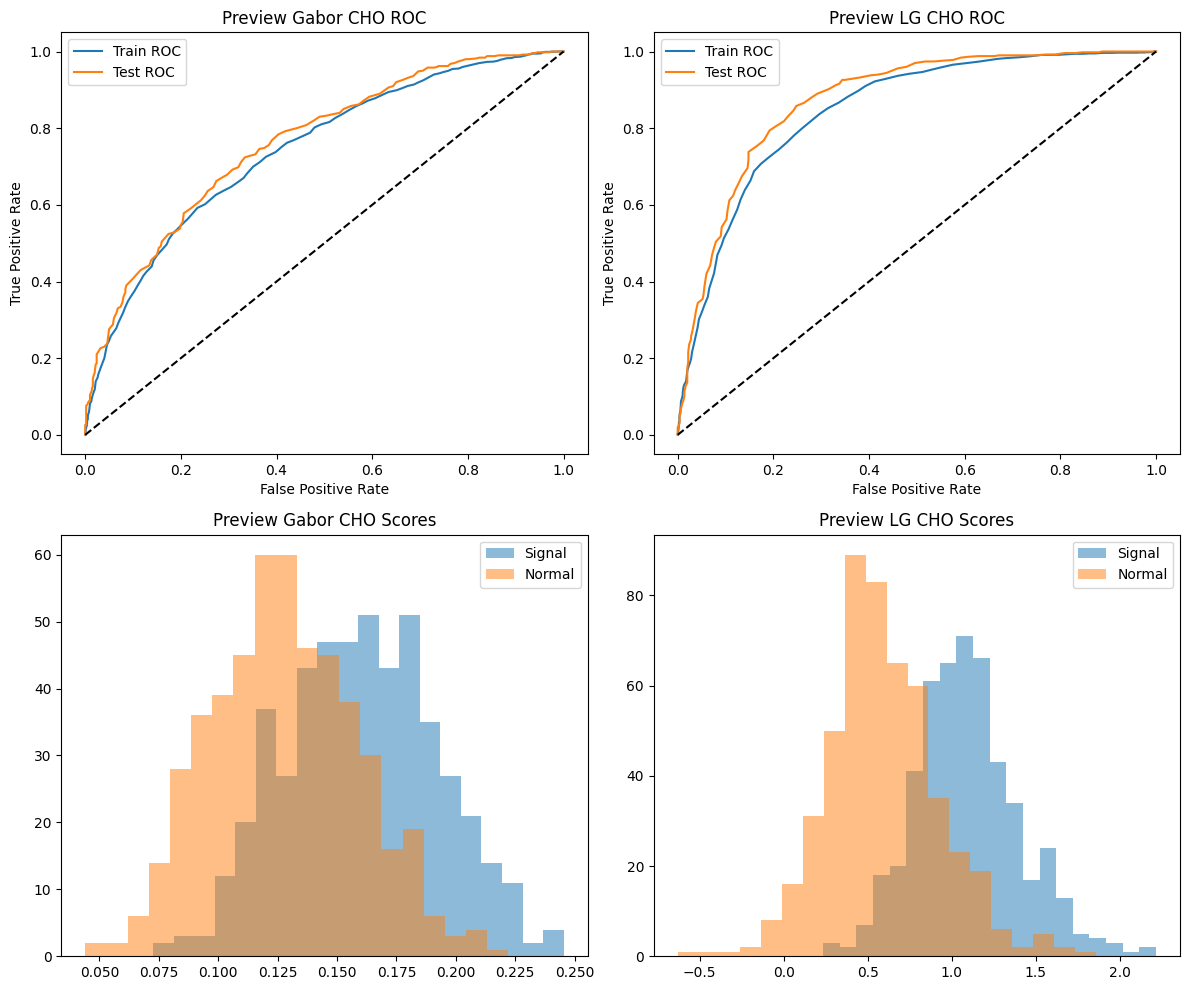

Using saved patch files for Original full sampling
Using saved patch files for Original 2x undersampling
Using saved patch files for Original 4x undersampling
Using saved patch files for Lesion amplitude 0.05
Using saved patch files for Lesion amplitude 0.10
Using saved patch files for Lesion amplitude 0.20


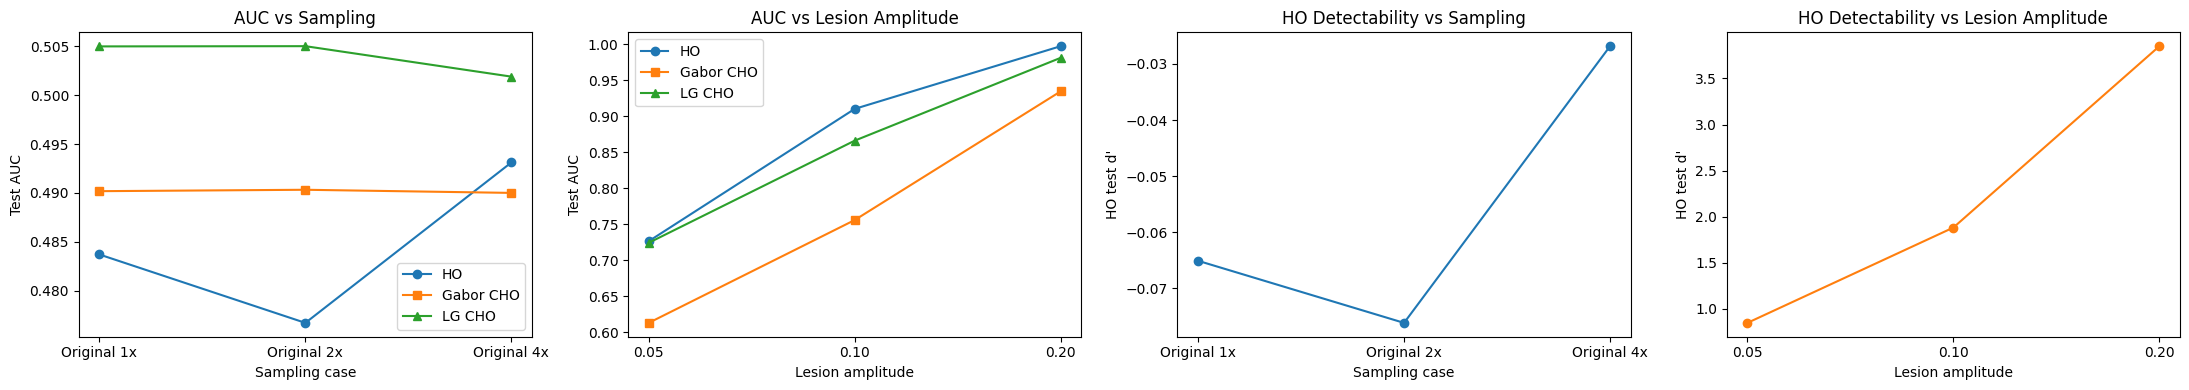

Original full sampling
  normalized_noise=0.000, raw_kspace_sigma=0.00, undersampling=1x
  HO d'=-0.065, HO AUC=0.484, Gabor CHO AUC=0.490, LG CHO AUC=0.505
  IQ metrics: MSE=0.000000 +/- 0.000000, SSIM=1.0000 +/- 0.0000
Original 2x undersampling
  normalized_noise=0.000, raw_kspace_sigma=0.00, undersampling=2x
  HO d'=-0.076, HO AUC=0.477, Gabor CHO AUC=0.490, LG CHO AUC=0.505
  IQ metrics: MSE=0.001132 +/- 0.000309, SSIM=0.8386 +/- 0.0173
Original 4x undersampling
  normalized_noise=0.000, raw_kspace_sigma=0.00, undersampling=4x
  HO d'=-0.027, HO AUC=0.493, Gabor CHO AUC=0.490, LG CHO AUC=0.502
  IQ metrics: MSE=0.003818 +/- 0.001055, SSIM=0.6712 +/- 0.0256
Lesion amplitude 0.05
  normalized_noise=0.100, raw_kspace_sigma=20.11, undersampling=2x
  HO d'=0.849, HO AUC=0.726, Gabor CHO AUC=0.613, LG CHO AUC=0.724
Lesion amplitude 0.10
  normalized_noise=0.100, raw_kspace_sigma=20.11, undersampling=2x
  HO d'=1.883, HO AUC=0.910, Gabor CHO AUC=0.756, LG CHO AUC=0.866
  IQ metrics: MSE=0

In [38]:
_, gabor_preview_train_roc_curve = build_roc_curve(
    gabor_preview_results['train_signal_scores'],
    gabor_preview_results['train_normal_scores'],
 )
_, gabor_preview_test_roc_curve = build_roc_curve(
    gabor_preview_results['test_signal_scores'],
    gabor_preview_results['test_normal_scores'],
 )
_, lg_preview_train_roc_curve = build_roc_curve(
    lg_preview_results['train_signal_scores'],
    lg_preview_results['train_normal_scores'],
 )
_, lg_preview_test_roc_curve = build_roc_curve(
    lg_preview_results['test_signal_scores'],
    lg_preview_results['test_normal_scores'],
 )

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1)
plt.plot([fp for fp, tp in gabor_preview_train_roc_curve], [tp for fp, tp in gabor_preview_train_roc_curve], label='Train ROC')
plt.plot([fp for fp, tp in gabor_preview_test_roc_curve], [tp for fp, tp in gabor_preview_test_roc_curve], label='Test ROC')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Preview Gabor CHO ROC')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot([fp for fp, tp in lg_preview_train_roc_curve], [tp for fp, tp in lg_preview_train_roc_curve], label='Train ROC')
plt.plot([fp for fp, tp in lg_preview_test_roc_curve], [tp for fp, tp in lg_preview_test_roc_curve], label='Test ROC')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Preview LG CHO ROC')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.subplot(2, 2, 3)
plt.hist(gabor_preview_results['test_signal_scores'], bins=20, alpha=0.5, label='Signal')
plt.hist(gabor_preview_results['test_normal_scores'], bins=20, alpha=0.5, label='Normal')
plt.title('Preview Gabor CHO Scores')
plt.legend()

plt.subplot(2, 2, 4)
plt.hist(lg_preview_results['test_signal_scores'], bins=20, alpha=0.5, label='Signal')
plt.hist(lg_preview_results['test_normal_scores'], bins=20, alpha=0.5, label='Normal')
plt.title('Preview LG CHO Scores')
plt.legend()

plt.tight_layout()
plt.show()

def build_iq_metrics_filepath(source_mode, lesion_intensity, noise_level, undersampling_factor):
    source_tag = build_source_tag(source_mode, lesion_intensity)
    return Path(
        f'.\\MRI\\iq_metrics_source_{source_tag}'
        f'_noise_{noise_level:.2f}_undersample_{undersampling_factor}.npz'
    )

def load_iq_metrics(source_mode, lesion_intensity, noise_level, undersampling_factor):
    filepath = build_iq_metrics_filepath(
        source_mode,
        lesion_intensity,
        noise_level,
        undersampling_factor,
    )
    if not filepath.exists():
        return None

    with np.load(filepath) as data:
        n_images = int(data['n_images']) if 'n_images' in data.files else None
        return {
            'mse_mean': float(data['mse_mean']),
            'mse_std': float(data['mse_std']),
            'ssim_mean': float(data['ssim_mean']),
            'ssim_std': float(data['ssim_std']),
            'n_images': n_images,
        }

def evaluate_saved_case(indices, train_size, test_size, source_mode, lesion_intensity, noise_level, undersampling_factor, gabor_width, lg_scale, progress_label=None):
    if progress_label is not None:
        print(f"Using saved patch files for {progress_label}")

    signal_patches, normal_patches = load_case_patches(
        source_mode,
        lesion_intensity,
        noise_level,
        undersampling_factor,
    )
    case_indices = np.asarray(indices[:train_size + test_size], dtype=int)
    split_data = split_case_data(
        signal_patches[case_indices],
        normal_patches[case_indices],
        train_size=train_size,
        test_size=test_size,
    )
    ho_case_results = fit_hotelling_observer(
        split_data['train_signal_patches'],
        split_data['train_normal_patches'],
        split_data['test_signal_patches'],
        split_data['test_normal_patches'],
    )
    gabor_case_results = fit_channelized_hotelling_observer(
        split_data['train_signal_patches'],
        split_data['train_normal_patches'],
        split_data['test_signal_patches'],
        split_data['test_normal_patches'],
        build_gabor_channels(patch_shape, gabor_width),
    )
    lg_case_results = fit_channelized_hotelling_observer(
        split_data['train_signal_patches'],
        split_data['train_normal_patches'],
        split_data['test_signal_patches'],
        split_data['test_normal_patches'],
        build_lg_channels(patch_shape, lg_scale),
    )
    return {
        'ho': ho_case_results,
        'gabor': gabor_case_results,
        'lg': lg_case_results,
    }

selected_gabor_width = globals().get('best_gabor_width', current_gabor_width)
selected_lg_scale = globals().get('best_lg_scale', current_lg_scale)
study_noise_level = globals().get('moderate_noise_level', reference_noise_level)

analysis_cases = [
    {
        'label': 'Original full sampling',
        'short_label': 'Original 1x',
        'source_mode': 'original',
        'lesion_intensity': None,
        'noise_level': 0.00,
        'undersampling_factor': 1,
        'case_group': 'sampling',
    },
    {
        'label': 'Original 2x undersampling',
        'short_label': 'Original 2x',
        'source_mode': 'original',
        'lesion_intensity': None,
        'noise_level': 0.00,
        'undersampling_factor': 2,
        'case_group': 'sampling',
    },
    {
        'label': 'Original 4x undersampling',
        'short_label': 'Original 4x',
        'source_mode': 'original',
        'lesion_intensity': None,
        'noise_level': 0.00,
        'undersampling_factor': 4,
        'case_group': 'sampling',
    },
    {
        'label': 'Lesion amplitude 0.05',
        'short_label': 'Lesion 0.05',
        'source_mode': 'lesion',
        'lesion_intensity': 0.05,
        'noise_level': study_noise_level,
        'undersampling_factor': reference_undersampling_factor,
        'case_group': 'intensity',
    },
    {
        'label': 'Lesion amplitude 0.10',
        'short_label': 'Lesion 0.10',
        'source_mode': 'lesion',
        'lesion_intensity': 0.10,
        'noise_level': study_noise_level,
        'undersampling_factor': reference_undersampling_factor,
        'case_group': 'intensity',
    },
    {
        'label': 'Lesion amplitude 0.20',
        'short_label': 'Lesion 0.20',
        'source_mode': 'lesion',
        'lesion_intensity': 0.20,
        'noise_level': study_noise_level,
        'undersampling_factor': reference_undersampling_factor,
        'case_group': 'intensity',
    },
]

analysis_results = []
for case in analysis_cases:
    evaluation_results = evaluate_saved_case(
        experiment_indices,
        train_size=train_size,
        test_size=test_size,
        source_mode=case['source_mode'],
        lesion_intensity=case['lesion_intensity'],
        noise_level=case['noise_level'],
        undersampling_factor=case['undersampling_factor'],
        gabor_width=selected_gabor_width,
        lg_scale=selected_lg_scale,
        progress_label=case['label'],
    )
    iq_metrics = load_iq_metrics(
        case['source_mode'],
        case['lesion_intensity'],
        case['noise_level'],
        case['undersampling_factor'],
    )
    analysis_results.append({
        **case,
        'raw_kspace_component_sigma': noise_level_to_raw_kspace_component_sigma(case['noise_level']),
        'ho_test_detectability': evaluation_results['ho']['test_detectability'],
        'ho_test_auc': evaluation_results['ho']['test_auc'],
        'gabor_test_auc': evaluation_results['gabor']['test_auc'],
        'lg_test_auc': evaluation_results['lg']['test_auc'],
        'iq_metrics': iq_metrics,
    })

sampling_results = [result for result in analysis_results if result['case_group'] == 'sampling']
intensity_results = [result for result in analysis_results if result['case_group'] == 'intensity']
analysis_summaries = analysis_results

fig, axes = plt.subplots(1, 4, figsize=(22, 4))

sampling_labels = [result['short_label'] for result in sampling_results]
axes[0].plot(sampling_labels, [result['ho_test_auc'] for result in sampling_results], marker='o', label='HO')
axes[0].plot(sampling_labels, [result['gabor_test_auc'] for result in sampling_results], marker='s', label='Gabor CHO')
axes[0].plot(sampling_labels, [result['lg_test_auc'] for result in sampling_results], marker='^', label='LG CHO')
axes[0].set_title('AUC vs Sampling')
axes[0].set_xlabel('Sampling case')
axes[0].set_ylabel('Test AUC')
axes[0].legend()

intensity_labels = [f"{result['lesion_intensity']:.2f}" for result in intensity_results]
axes[1].plot(intensity_labels, [result['ho_test_auc'] for result in intensity_results], marker='o', label='HO')
axes[1].plot(intensity_labels, [result['gabor_test_auc'] for result in intensity_results], marker='s', label='Gabor CHO')
axes[1].plot(intensity_labels, [result['lg_test_auc'] for result in intensity_results], marker='^', label='LG CHO')
axes[1].set_title('AUC vs Lesion Amplitude')
axes[1].set_xlabel('Lesion amplitude')
axes[1].set_ylabel('Test AUC')
axes[1].legend()

axes[2].plot(sampling_labels, [result['ho_test_detectability'] for result in sampling_results], marker='o', color='tab:blue')
axes[2].set_title("HO Detectability vs Sampling")
axes[2].set_xlabel('Sampling case')
axes[2].set_ylabel("HO test d'")

axes[3].plot(intensity_labels, [result['ho_test_detectability'] for result in intensity_results], marker='o', color='tab:orange')
axes[3].set_title("HO Detectability vs Lesion Amplitude")
axes[3].set_xlabel('Lesion amplitude')
axes[3].set_ylabel("HO test d'")

plt.tight_layout()
plt.show()

for result in analysis_results:
    print(result['label'])
    print(
        f"  normalized_noise={result['noise_level']:.3f}, "
        f"raw_kspace_sigma={result['raw_kspace_component_sigma']:.2f}, "
        f"undersampling={result['undersampling_factor']}x"
    )
    print(
        f"  HO d'={result['ho_test_detectability']:.3f}, "
        f"HO AUC={result['ho_test_auc']:.3f}, "
        f"Gabor CHO AUC={result['gabor_test_auc']:.3f}, "
        f"LG CHO AUC={result['lg_test_auc']:.3f}"
    )
    if result['iq_metrics'] is not None:
        print(
            f"  IQ metrics: MSE={result['iq_metrics']['mse_mean']:.6f} +/- {result['iq_metrics']['mse_std']:.6f}, "
            f"SSIM={result['iq_metrics']['ssim_mean']:.4f} +/- {result['iq_metrics']['ssim_std']:.4f}"
        )